In [14]:
import os
import glob
import pandas as pd
import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt

In [ ]:
FOLDER = "."

excel_files = glob.glob(os.path.join(FOLDER, "*.xlsx"))

print(f"Found {len(excel_files)} Excel file:")
for f in excel_files:
    print(" -", os.path.basename(f))

all_data = {}

for fpath in excel_files:
    key = os.path.splitext(os.path.basename(fpath))[0]
    all_data[key] = pd.read_excel(fpath, sheet_name=None)
    print(f"[OK] {key} -> sheets: {list(all_data[key].keys())}")

# Validation class 1 — Thermo-Hydraulic Validation (THV).
DHN_THV_3G_R_S_BASE = all_data["DHN_THV_3G_R_S_BASE_results"]
DHN_THV_3G_L_S_BASE = all_data["DHN_THV_3G_L_S_BASE_results"]
DHN_THV_3G_M_S_BASE = all_data["DHN_THV_3G_M_S_BASE_results"]

# Validation class 2 — Technology Assessment (TG).
DHN_TG_3G_M_M_BASE = all_data["DHN_TG_3G_M_M_BASE_results"]
DHN_TG_4G_M_M_BASE = all_data["DHN_TG_4G_M_M_BASE_results"]
DHN_TG_5G_M_M_BASE = all_data["DHN_TG_5G_M_M_BASE_results"]

# Validation class 3 — Computational Scalability (CS).
DHN_CS_3G_M_L_BASE = all_data["DHN_CS_3G_M_L_BASE_results"]

networks = {
    "DHN_THV_3G_R_S_BASE": DHN_THV_3G_R_S_BASE,
    "DHN_THV_3G_L_S_BASE": DHN_THV_3G_L_S_BASE,
    "DHN_THV_3G_M_S_BASE": DHN_THV_3G_M_S_BASE,
    "DHN_TG_3G_M_M_BASE":  DHN_TG_3G_M_M_BASE,
    "DHN_TG_4G_M_M_BASE":  DHN_TG_4G_M_M_BASE,
    "DHN_TG_5G_M_M_BASE":  DHN_TG_5G_M_M_BASE,
    "DHN_CS_3G_M_L_BASE":  DHN_CS_3G_M_L_BASE,
}

for net_name, sheets in networks.items():
    for sheet_name, df in sheets.items():
        first_col = df.columns[0]
        df = df.rename(columns={first_col: "timestep"})
        df = df.set_index("timestep")
        sheets[sheet_name] = df

Found 7 Excel file:
 - DHN_CS_3G_M_L_BASE_results.xlsx
 - DHN_TG_3G_M_M_BASE_results.xlsx
 - DHN_TG_4G_M_M_BASE_results.xlsx
 - DHN_TG_5G_M_M_BASE_results.xlsx
 - DHN_THV_3G_L_S_BASE_results.xlsx
 - DHN_THV_3G_M_S_BASE_results.xlsx
 - DHN_THV_3G_R_S_BASE_results.xlsx


In [11]:
THV_NETWORKS = {
    "Radial": DHN_THV_3G_R_S_BASE,
    "Ring":   DHN_THV_3G_L_S_BASE,
    "Mesh":   DHN_THV_3G_M_S_BASE,
}

TG_NETWORKS = {
    "3G":     DHN_TG_3G_M_M_BASE,
    "4G":     DHN_TG_4G_M_M_BASE,
    "5G":     DHN_TG_5G_M_M_BASE,
}

CS_NETWORKS = {
    "Small":  DHN_THV_3G_M_S_BASE,
    "Medium": DHN_TG_3G_M_M_BASE,
    "Large":  DHN_CS_3G_M_L_BASE,
}

In [12]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    print(f"[SAVED] {name}.png")

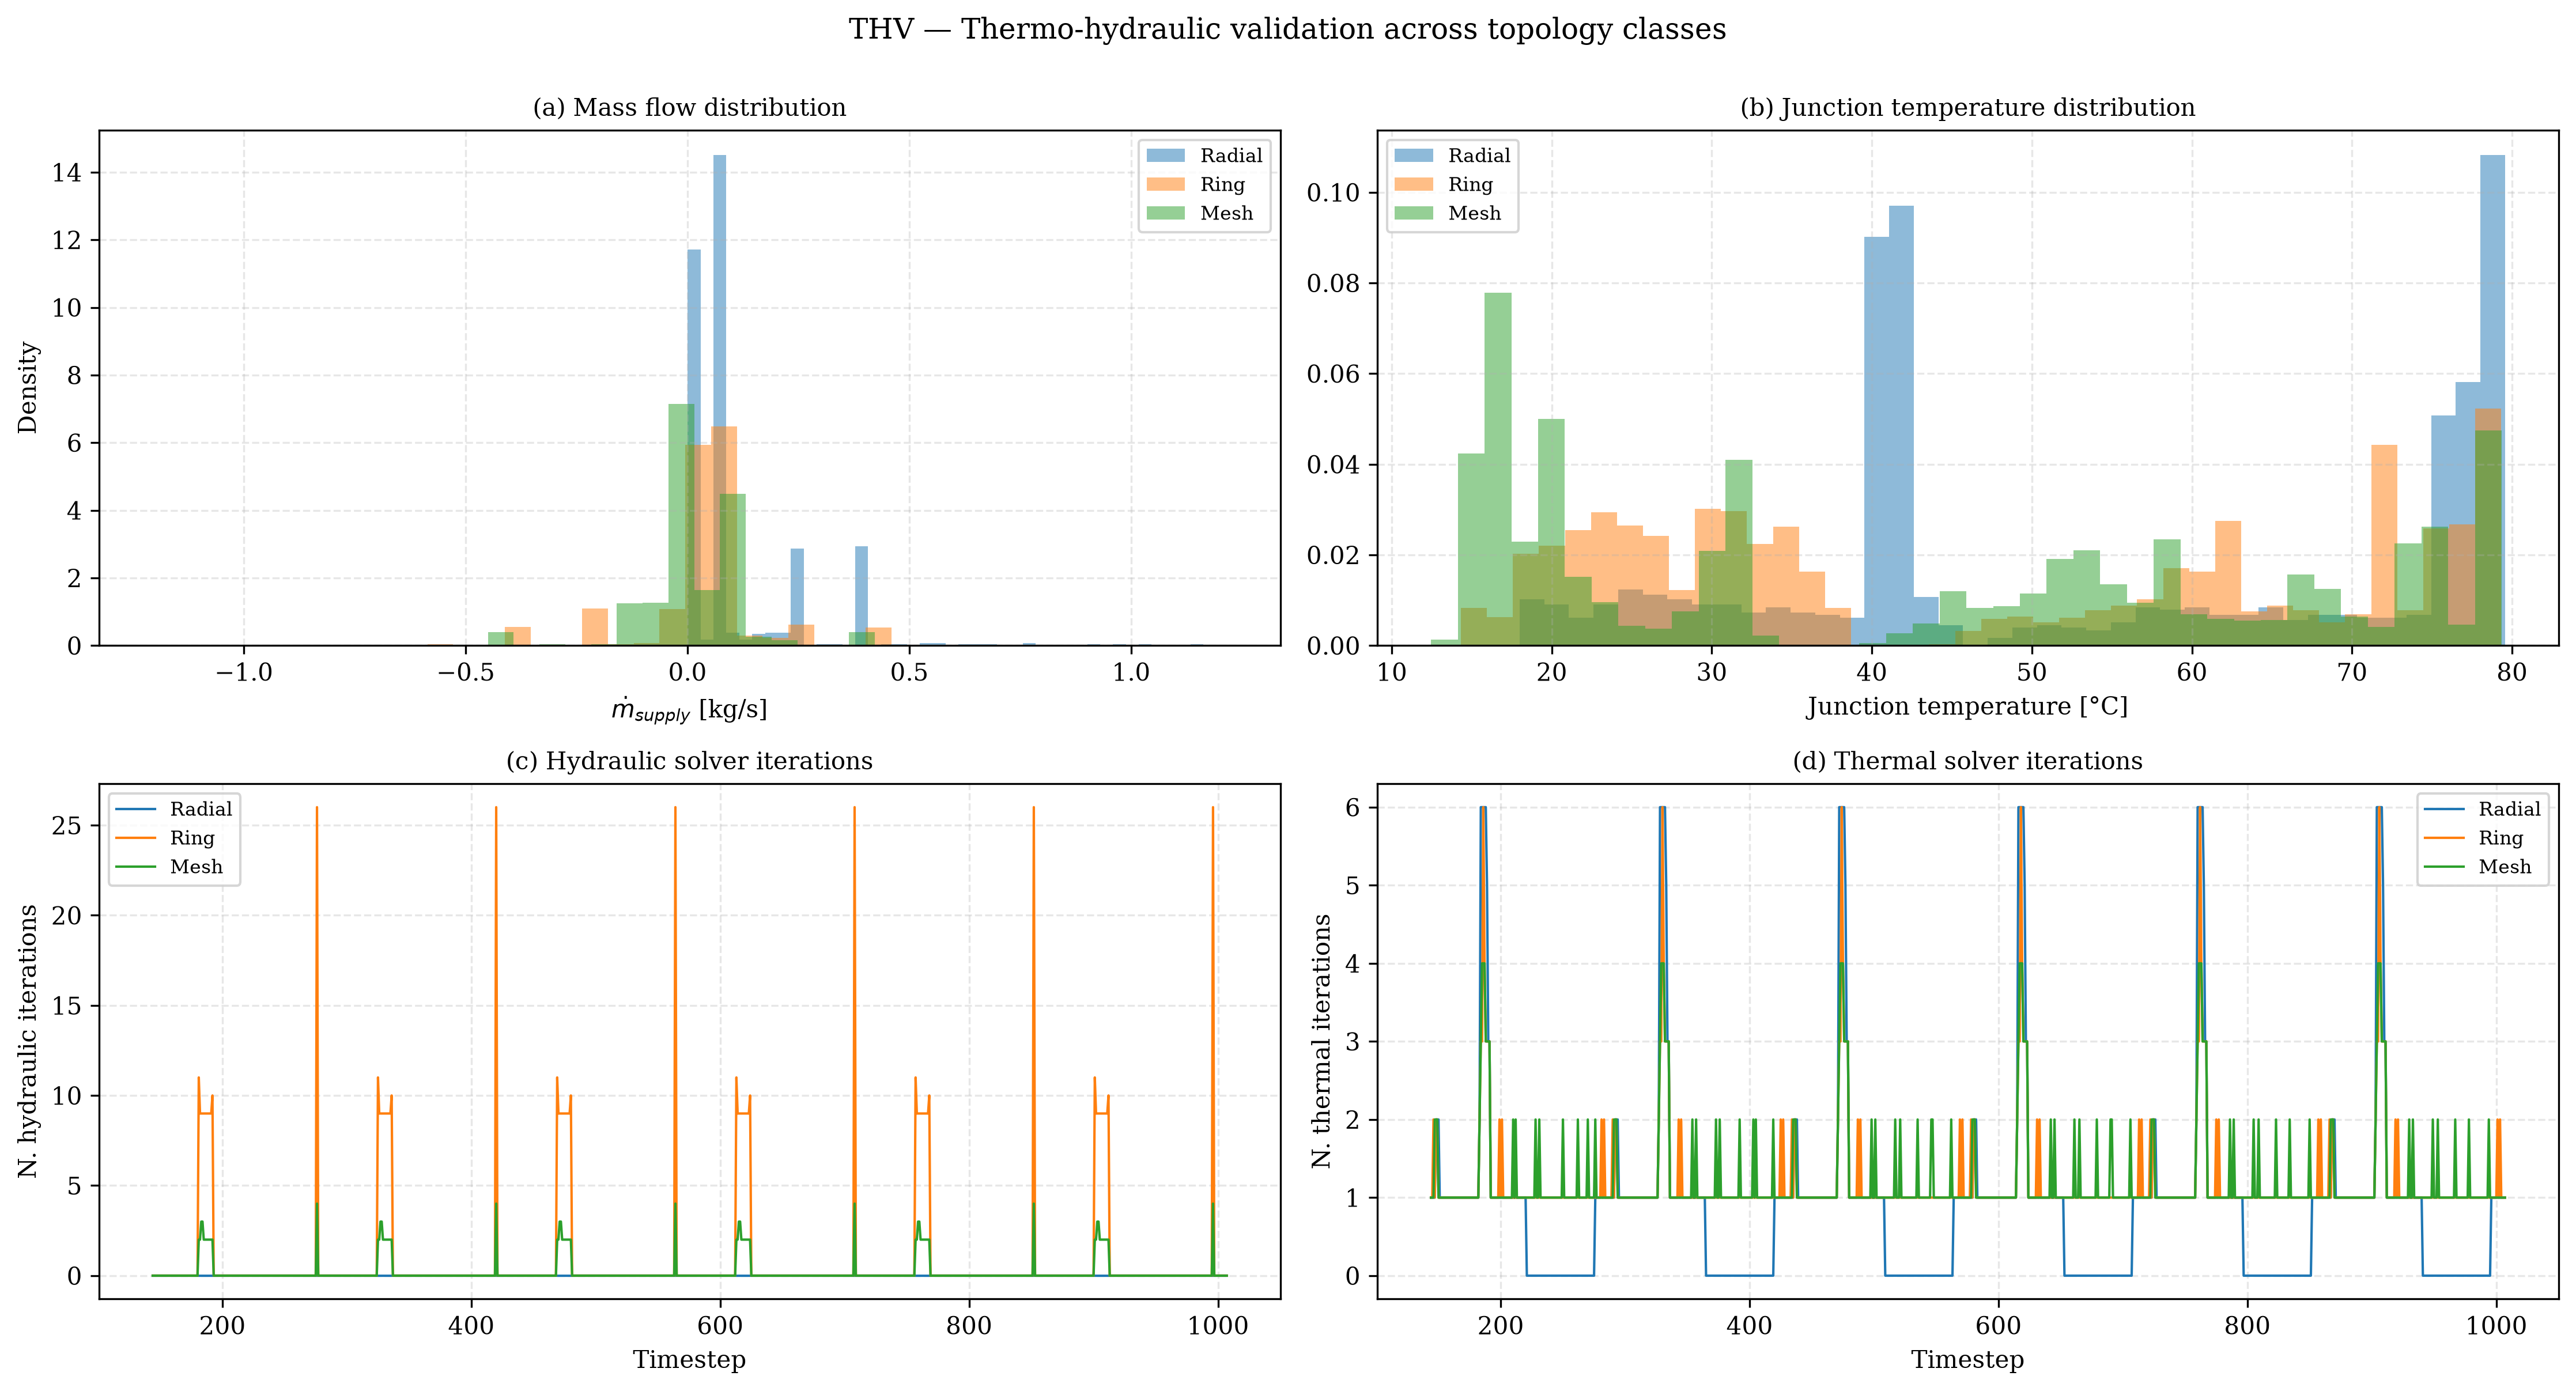

        mean_hyd_iter  max_hyd_iter  mean_therm_iter  max_therm_iter  \
Radial          0.000           0.0            0.875             6.0   
Ring            0.951          26.0            1.194             6.0   
Mesh            0.208           4.0            1.213             4.0   

        eta_network_%  Q_losses_MWh  
Radial         70.877         4.296  
Ring           62.454         6.246  
Mesh           55.141         8.203  


In [13]:
# THV results
COLORS = {"Radial": "tab:blue", "Ring": "tab:orange", "Mesh": "tab:green"}

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# (a) Mass flow distribution
for label, sheets in THV_NETWORKS.items():
    vals = sheets["pipe_s_mdot_kgs"].values.flatten()
    axes[0, 0].hist(vals, bins=40, alpha=0.5, label=label, color=COLORS[label], density=True)
axes[0, 0].set_xlabel(r"$\dot{m}_{supply}$ [kg/s]")
axes[0, 0].set_ylabel("Density")
axes[0, 0].set_title("(a) Mass flow distribution")
axes[0, 0].legend(fontsize=8)

# (b) Junction temperature distribution
for label, sheets in THV_NETWORKS.items():
    vals = sheets["junction_T_degC"].values.flatten()
    axes[0, 1].hist(vals, bins=40, alpha=0.5, label=label, color=COLORS[label], density=True)
axes[0, 1].set_xlabel("Junction temperature [°C]")
axes[0, 1].set_title("(b) Junction temperature distribution")
axes[0, 1].legend(fontsize=8)

# (c) Hydraulic solver iterations
for label, sheets in THV_NETWORKS.items():
    log = sheets["solver_iteration"]
    axes[1, 0].plot(log.index, log["hydraulics_iterations"], label=label, color=COLORS[label], linewidth=1.0)
axes[1, 0].set_xlabel("Timestep")
axes[1, 0].set_ylabel("N. hydraulic iterations")
axes[1, 0].set_title("(c) Hydraulic solver iterations")
axes[1, 0].legend(fontsize=8)

# (d) Thermal solver iterations
for label, sheets in THV_NETWORKS.items():
    log = sheets["solver_iteration"]
    axes[1, 1].plot(log.index, log["thermal_iterations"], label=label, color=COLORS[label], linewidth=1.0)
axes[1, 1].set_xlabel("Timestep")
axes[1, 1].set_ylabel("N. thermal iterations")
axes[1, 1].set_title("(d) Thermal solver iterations")
axes[1, 1].legend(fontsize=8)

fig.suptitle("THV — Thermo-hydraulic validation across topology classes", y=1.00)
plt.tight_layout()
plt.show()


rows = {}
for label, sheets in THV_NETWORKS.items():
    log = sheets["solver_iteration"]
    eb  = sheets["energy_balance"].iloc[0]

    rows[label] = {
        "mean_hyd_iter":   log["hydraulics_iterations"].mean(),
        "max_hyd_iter":    log["hydraulics_iterations"].max(),
        "mean_therm_iter": log["thermal_iterations"].mean(),
        "max_therm_iter":  log["thermal_iterations"].max(),
        "eta_network_%":   eb["eta_network"] * 100,
        "Q_losses_MWh":    eb["Q_losses_MWh"],
    }

thv_summary_df = pd.DataFrame(rows).T
print(thv_summary_df.round(3))